
# Outline
- In the last session we learned how to use optimize
- Now we re-write our SSE function to fit lines with slope and intercept
  - Not just horizontal lines
<br> 

- How do we know if the line we fit is any good?
  - `optimize` will always fit _some_ line to a cloud of points
  - That doesn't mean the points are particularly close to the line
    - The points could fall all virtually on the line.
    - That would be a good fit
    - The points could be in a big cloud around the line, with many possible other lines that are about as good
    - That would be a poor fit
<br>

  - An amorphous cloud of points with no direction does not have a clear 'best fit' line.  Lines going in all directions fit about equally well.
  - A big cloud allows more lines that all fit the cloud (because none fit particularly well)
  - A strongly oriented set of points will allow only a limited set of lines that fit well
  - How do we know if the slope for our line is reliable?
<br>

- Answer:  A permutation test!!! -- 2 questions:
  - What do we mix up?
  - What is the 'critical value' that we want to save?
    - Think about what we what information we want about the line

# Python tools: 

## Useful Python 1 -- Conditional statements

Conditional statements are of the fundamental programming tools - you may have already discovered them...

```python
if ( [boolean expression ):
      do this if boolean expression is True
else:
      do this if boolean expression is False
```

Decision points in algorithms need 'if else' statements

- Note ':' after the boolean expression and after 'else'
- Note indenting
    - Indented section after 'if' is only run if boolean expression is True
    - Indented section after 'else' is only run if boolean expression is False

## Long conditional statements

Conditional statements can be longer, e.g.


In [1]:
PostCodePrefix = "B"

if(PostCodePrefix == "B"):
    City = "Birmingham"
elif(PostCodePrefix == "EH"):
    City = "Edinburgh"
elif(PostCodePrefix == "YO"):
    City = "York"
else:
    City = "Don't know this place"
print("PostCode starts with: ",PostCodePrefix," City is: ",City)

PostCode starts with:  B  City is:  Birmingham


- Notice that there is a boolean expression after both 'if' and 'elif'
- There is no boolean expression after 'else'

## Useful Python 2  -- Sorting data frames

Use the 'sort_values' method to sort a dataframe based on some column, e.g.:

```
my_df.sort_values("sort_column",ascending=False) # sort with highest value at the top
```

## Useful Python 3 -- value_counts

To get counts of how many times each value occurs in a column, use the 'value_counts' method.  E.g.

```
fire_country_counts = wildfire_incidents["country"].value_counts()
```

If the dataframe lists individual fire episodes and each episode has a country listed, the value_counts() method will tell you how many fires occurred in each country.

e.g.
| Fire name | Country | date |
|----------|------------|----------|
| Buongiorno | Italy | 15-8-2024 |
| Palisades | USA | 20-9-2024 |
| Champagne | France | 8-7-2024 |
| Lohansa County | USA | 11-7-2024 |
| Big swampy | USA | 28-9-2024 |
| Caffelatte | Italy | 25-7-2024 |
| Tramonte | Italy | 14-7-2024 |
| Acropolis | Greece | 13-6-2024|

This would produce 
| Country | count |
|---------|--------|
| Italy | 3 |
| USA | 2 |
| Greece | 1 |
| France | 1 |


## Useful Python 4 -- dropna()

The 'dropna' method will drop rows that have missing values in any position

```
no_missing_values_data = missing_values_data.dropna()
```

- There is an option to drop only if specific columns have missing values: see the option `subset = `
- There is an option to drop only if all values are NA or if any values are NA: the the option `how = `



# Fitting lines - (not just horizontal lines)

### Reminder - formula for a line


The equation for a line is:
    
$$y = mx + b$$

Where:  
y = a value from you data that you want to predict  
x = a value from your data that you think predicts y (e.g. if ```y=weight``` ```x``` might be ```height```)  
<br>

m = the slope of the line relating x and y  (how many kilos does every cm of height add?)  
b = the y intercept of the line -- where the line touches the y axis  

#### So we have _two_ values to change this time
- **The slope and the intercept**

Compare to the case for the horizontal line (last time) -- we just had to optimize one value

### Vevox -- Conceptually how would you calculate the error for an arbitrary line?
- any line, not just a horizontal line

### Vevox -- How would you use optimize to fit the best line to a set of points?
- Remember, the optimize statement is

```python
opt_mean=optimize.minimize(sse,[11],args=y_values)
```

| Part         | What is it?                                |
|:-------------|:-------------------------------------------|
| values to adjust    | The value(s) that python changes to find the minimum.  This can be an array of values if you are asking python to adjust more than one value.  |
| sse               | the **function** (NOT a variable) **we have written** that calculates the ONE value we want to minimize |
| an **array**      | the starting values for the values that 'optimize' can change  - here we have just one value - our first guess - 11 |
| args=y_values     | these are other arguments that get passed to sse, but not changed by optimize |

Some of the arguments will change when you are optimizing an arbitrary line

- What do you need to pass as 'args'?
  

In [141]:
import numpy as np
import pandas as pd
import scipy.optimize as optimize
import matplotlib.pyplot as plt
import seaborn as sns

#### Here are some points to use:

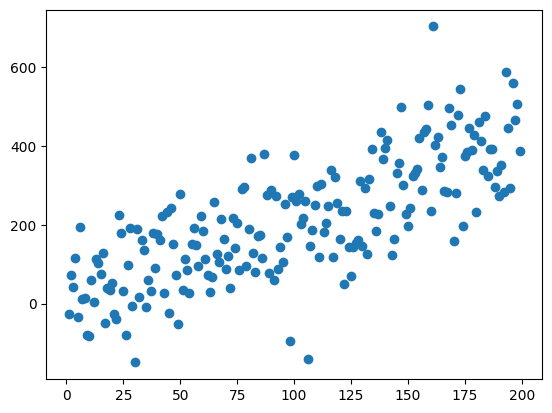

In [142]:
line_to_fit = pd.read_csv("line_to_fit.csv")
plt.scatter(line_to_fit["x"],line_to_fit["y"])

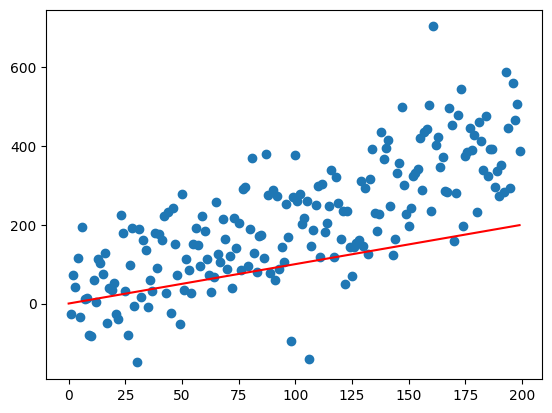

In [143]:
# let's start with a guess for a line

slope = 1
intercept = 0

x_values = np.arange(0,200)
line_prediction = x_values * slope + intercept

plt.scatter(line_to_fit["x"],line_to_fit["y"])
plt.plot(x_values,line_prediction, color="red")

In [7]:
line_to_fit

,Unnamed: 0,x,y
0,0,1,-26.268673
1,1,2,73.411854
2,2,3,43.046200
3,3,4,116.136443
4,4,5,-33.415273
...,...,...,...
194,194,195,292.240603
195,195,196,559.499619
196,196,197,465.119674
197,197,198,506.076281


### Start small: Take just one point - calculate the error

line_to_fit[3]:  x = 4, y = 116.136443  
predicted?  
error?

In [14]:
real_x = 4
real_y = 116.136443

predicted = real_x * slope + intercept
error = predicted - real_y
# remember when we sum errors we need to square so +error and -error do not cancel
squared_error = error**2

print(f"real: x = {real_x}  y = {real_y}")
print(f"pred: x = {real_x}  y = {predicted}")
print(f"error: predicted ({predicted}) - real ({real_y}) = {predicted} - {real_y} = {predicted - real_y}")
print(f"squared error: {squared_error}")

real: x = 4  y = 116.136443
pred: x = 4  y = 4
error: predicted (4) - real (116.136443) = 4 - 116.136443 = -112.136443
squared error: 12574.581848692249


#### Steps

- Write your error function - SSE for points on a line
  - Loop through all points and calculate an error value for each
    - Get the x value from the point
    - Get the y value from the same point
    - Use the slope and intercept for the line (pass these to the function)
      - Calculate the line's y-value using the point's x-value
      - Remember $line\_y\_value\ =\ intercept\ +\ (slope\ \times\ point\_x\_value)$
    - Calculate the squared distance between the line's y-value and the point's y-value
    - Store this value
  - Sum up the error values 


#### NOTE: Everything is the same as your previous SSE, _except_ you need to calculate the y value from the line, not just use the horizontal guess value

In [ ]:
# write your SSE function here

#### Once you have the SSE function written, use it with optimize minimize to get the best fit line

In [ ]:
# write the optimize statement that uses your sse here

In [285]:
# check your result with a stats package

import statsmodels.api as sm

x_values = line_to_fit["x"]
y_values = line_to_fit["y"]
x_values_OLS = sm.add_constant(x_values) # this adds an intercept to the model

results=sm.OLS(y_values,x_values_OLS).fit()
# notice that y values come first here
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.143
Model:                            OLS   Adj. R-squared:                  0.072
Method:                 Least Squares   F-statistic:                     2.006
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.182
Time:                        01:01:28   Log-Likelihood:                -62.505
No. Observations:                  14   AIC:                             129.0
Df Residuals:                      12   BIC:                             130.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -5.6359     12.820     -0.440      0.6

/Users/a.c.olson@bham.ac.uk/Documents/teach/IntroToDataScience/26-27course/.venv/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=14
  res = hypotest_fun_out(*samples, **kwds)


#### The optimized values are in "x"

- 2.029 is the optimized value for the slope
- 7.843 is the optimized value for the intercept
- NOTE:  see x: [..., ...]

Do these make sense?
- Does the line cross the y-axis at about 7.843?
  - Hard to see here because of the scale, but looks close to zero which is about right when the scale is big
- Does the line go up 2 y values for every x value (e.g. is [100,200] on the line)?
  - Yes - looks right

#### Practice

- The cell below has a routine that makes lines
  - You set the slope (see ```gen_slope```)
  - You set the intercept (see ```gen_intercept```)
  - You set a noise level -- Noisy lines will have points further from the line used to generate the data
  - You set the number of points to generate
  - The data end up in the file: ```line_to_fit2.csv```
- Practice fitting lines to data
  - Try noisy/less noisy data
  - Try more/fewer points
  - The slope and intercept of the fitted line won't match exactly the slope and intercept you set to generate the data
    - Remember that there is noise
    - Noise will change the fitted values
    - More noise = slope/intercept of fitted line may be further from the values used to generate the data
    - What about more/fewer points?

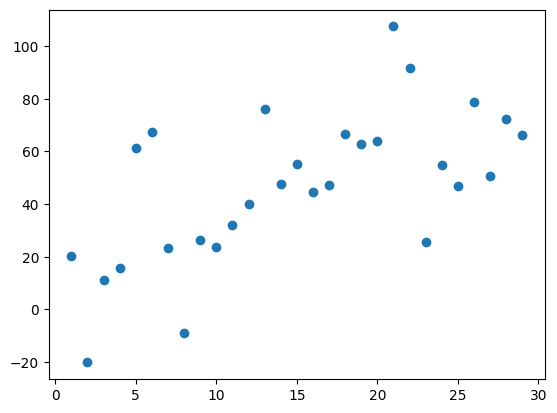

In [152]:
def make_a_noisy_line(slope,intercept,x_values,noise):
    y=np.zeros(len(x_values))
    noise = np.random.normal(0,noise,len(x_values))
    y = slope*x_values + intercept + noise
    return(y)

gen_slope = 2
gen_intercept = 10

noise = 25
number_of_values = 30
x_values = np.arange(1,number_of_values,1)
# reshape(-1,1) puts the values into a single column, rather than in an array
# LinearRegression below uses column values (because usually you'll be working with a column of a dataframe)
y_values = make_a_noisy_line(gen_slope,gen_intercept,x_values,noise).reshape(-1,1)

plt.scatter(x_values,y_values)

line_to_fit = pd.DataFrame()
line_to_fit["x"] = x_values
line_to_fit["y"] = y_values

line_to_fit.to_csv("line_to_fit2.csv")

In [162]:
line_to_fit = pd.read_csv("line_to_fit2.csv")
result = optimize.minimize(sse,[1,5], args=(x_values,y_values))
result

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 13976.840832348755
        x: [ 2.124e+00  1.472e+01]
      nit: 5
      jac: [ 2.441e-04  0.000e+00]
 hess_inv: [[ 6.085e-05 -4.301e-05]
            [-4.301e-05  8.223e-04]]
     nfev: 39
     njev: 13

In [163]:
# check the result with a stats package

import statsmodels.api as sm

x_values_OLS = sm.add_constant(x_values) # this adds an intercept to the model

results=sm.OLS(y_values,x_values_OLS).fit()
# notice that y values come first here
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.396
Model:                            OLS   Adj. R-squared:                  0.373
Method:                 Least Squares   F-statistic:                     17.68
Date:                Fri, 20 Nov 2026   Prob (F-statistic):           0.000257
Time:                        00:35:26   Log-Likelihood:                -130.73
No. Observations:                  29   AIC:                             265.5
Df Residuals:                      27   BIC:                             268.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         14.7197      8.673      1.697      0.1

#### NOTE: in the printout above
- `const` is the intercept and
- `x` is the slope

## Permutation testing for regression

#### Example:  Cholesterol and heart disease (caution: These data are made up)

Text(0.5, 0, 'cholesterol')

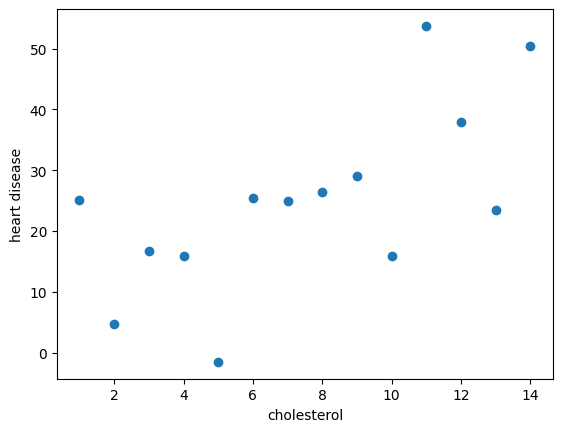

In [298]:
# make some data to fit - first, simulate data where there is a relationship

def make_a_noisy_line(slope,intercept,x_values,noise):
    y=np.zeros(len(x_values))
    noise = np.random.normal(0,noise,len(x_values))
    y = slope*x_values + intercept + noise
    return(y)

gen_slope = 2 # choose a slope for your line
gen_intercept = 10 # choose an intercept for your line

noise = 12 # scatter the points around the line
number_of_values = 15

x_values = np.arange(1,number_of_values,1)
# reshape(-1,1) puts the values into a single column, rather than in an array
# LinearRegression below uses column values (because usually you'll be working with a column of a dataframe)
y_values = make_a_noisy_line(gen_slope,gen_intercept,x_values,noise).reshape(-1,1)

line_to_fit = pd.DataFrame()
line_to_fit["x"] = x_values
line_to_fit["y"] = y_values

plt.scatter(line_to_fit["x"], line_to_fit["y"])
# let's call y 'heart disease'
plt.ylabel("heart disease")
# let's call x 'cholesterol'
plt.xlabel("cholesterol")

In [299]:
result = optimize.minimize(sse,[1,5], args=(line_to_fit["x"],line_to_fit["y"]))
result

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 1705.0168182372656
        x: [ 2.394e+00  6.915e+00]
      nit: 10
      jac: [ 1.526e-05  0.000e+00]
 hess_inv: [[ 1.238e-04 -5.165e-04]
            [-5.165e-04  2.579e-02]]
     nfev: 39
     njev: 13

slope: 2.393851118735151 intercept: 6.915185957019985


Text(0.5, 0, 'cholesterol')

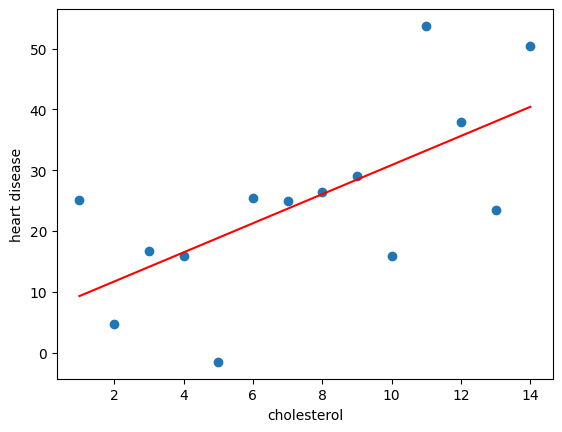

In [300]:
# predict values and show the predicted (best fit) line

slope = result["x"][0]
intercept = result["x"][1]
print(f"slope: {slope} intercept: {intercept}")

predicted_values = slope * line_to_fit["x"] + intercept

plt.scatter(line_to_fit["x"], line_to_fit["y"])
plt.plot(line_to_fit["x"],predicted_values,color="red")
# let's call y 'heart disease'
plt.ylabel("heart disease")
# let's call x 'cholesterol'
plt.xlabel("cholesterol")

In [301]:
x_values_OLS = sm.add_constant(line_to_fit["x"]) # this adds an intercept to the model
y_values = line_to_fit["y"]

results=sm.OLS(y_values,x_values_OLS).fit()
# notice that y values come first here
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.433
Model:                            OLS   Adj. R-squared:                  0.386
Method:                 Least Squares   F-statistic:                     9.175
Date:                Fri, 20 Nov 2026   Prob (F-statistic):             0.0105
Time:                        01:06:27   Log-Likelihood:                -53.481
No. Observations:                  14   AIC:                             111.0
Df Residuals:                      12   BIC:                             112.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.9152      6.729      1.028      0.3

/Users/a.c.olson@bham.ac.uk/Documents/teach/IntroToDataScience/26-27course/.venv/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=14
  res = hypotest_fun_out(*samples, **kwds)


## That looks like there is a relationship
### higher cholesterol is associated with higher levels of heart disease

## What would it look like if there is not a relationship?

Text(0.5, 0, 'cholesterol')

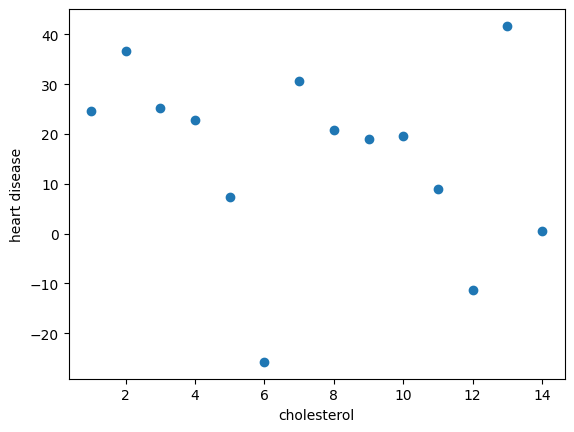

In [304]:
# simulate data where there is no relationship or a weak relationship 
# Repeat this code and the cells below a number of times to see how the
# red 'line of best fit' changes when there is no relationship/a weak relationship

def make_a_noisy_line(slope,intercept,x_values,noise):
    y=np.zeros(len(x_values))
    noise = np.random.normal(0,noise,len(x_values))
    y = slope*x_values + intercept + noise
    return(y)

gen_slope = 1 # choose a slope for your line
gen_intercept = 10 # choose an intercept for your line

noise = 25 # scatter the points around the line
number_of_values = 15

x_values = np.arange(1,number_of_values,1)
# reshape(-1,1) puts the values into a single column, rather than in an array
# LinearRegression below uses column values (because usually you'll be working with a column of a dataframe)
y_values = make_a_noisy_line(gen_slope,gen_intercept,x_values,noise).reshape(-1,1)

line_to_fit = pd.DataFrame()
line_to_fit["x"] = x_values
line_to_fit["y"] = y_values

plt.scatter(line_to_fit["x"], line_to_fit["y"])
# let's call y 'heart disease'
plt.ylabel("heart disease")
# let's call x 'cholesterol'
plt.xlabel("cholesterol")

### Even if there is no relationship we can still fit a line

In [305]:
result = optimize.minimize(sse,[1,5], args=(line_to_fit["x"],line_to_fit["y"]))
result

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 4127.255027452028
        x: [-1.092e+00  2.398e+01]
      nit: 7
      jac: [ 0.000e+00  0.000e+00]
 hess_inv: [[ 2.609e-03 -1.992e-02]
            [-1.992e-02  1.861e-01]]
     nfev: 60
     njev: 20

In [306]:
slope = result["x"][0]
intercept = result["x"][1]
print(f"slope: {slope} intercept: {intercept}")

predicted_values = slope * x_values + intercept

slope: -1.0917069652516327 intercept: 23.981424061879224


In [307]:
# check the result with a stats package

x_values_OLS = sm.add_constant(line_to_fit["x"]) # this adds an intercept to the model
y_values = line_to_fit["y"]

results=sm.OLS(y_values,x_values_OLS).fit()
# notice that y values come first here
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                 -0.017
Method:                 Least Squares   F-statistic:                    0.7883
Date:                Fri, 20 Nov 2026   Prob (F-statistic):              0.392
Time:                        01:06:57   Log-Likelihood:                -59.669
No. Observations:                  14   AIC:                             123.3
Df Residuals:                      12   BIC:                             124.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         23.9814     10.469      2.291      0.0

/Users/a.c.olson@bham.ac.uk/Documents/teach/IntroToDataScience/26-27course/.venv/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=14
  res = hypotest_fun_out(*samples, **kwds)


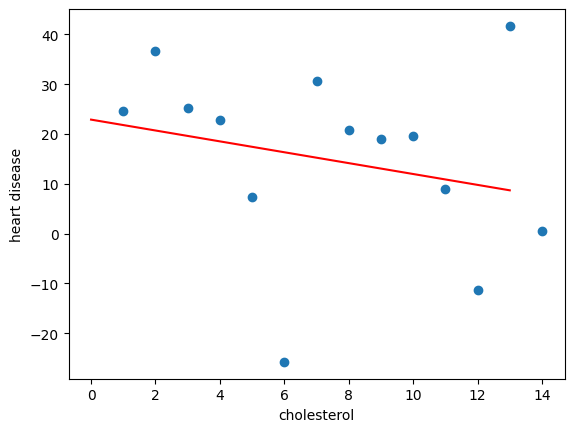

In [308]:
plt.scatter(line_to_fit["x"], line_to_fit["y"])
# let's call y 'heart disease'
plt.ylabel("heart disease")
# let's call x 'cholesterol'
plt.xlabel("cholesterol")

plt.plot(predicted_values,color="red")

## Permutation testing - How do we know if a set of points has a reliable direction?
## i.e. Does the slope reflect a real direction in the points? (Is it statistically significant?)
- Remember we mix up the values to destroy differences/relationships and create a 'no difference' or 'no relationship' world.
- Then we test whether the real world is different from that
  - Hypothesis:  Cholesterol is related to the incidence of heart disease
  - Null hypothesis:  Cholesterol has nothing to do with heart disease - no relationship</p> <br>


#### What can we randomize (mix up/permute) to destroy any systematic relationship between cholesterol and heart disease?
- It might help to think about a situation where you have a measure that gets higher with time
- What can we mix up that would destroy that systematic increase?

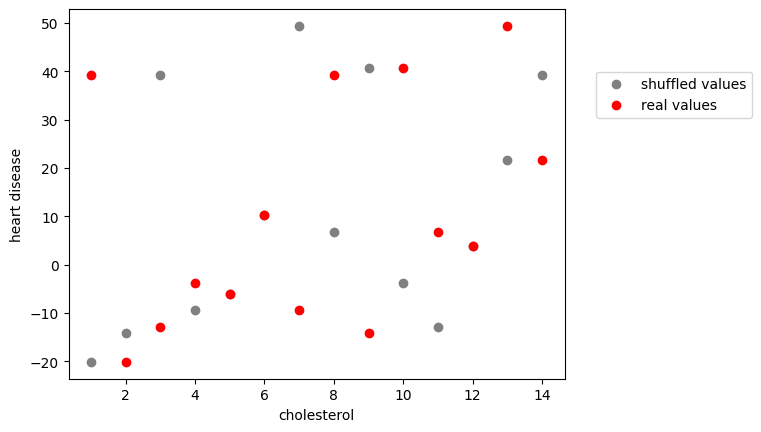

In [279]:
line_to_fit["shuffle_x"] = np.random.permutation(line_to_fit["x"]).copy()
plt.scatter(line_to_fit["shuffle_x"],line_to_fit["y"], color = "grey",label="shuffled values")
# shuffled values are in grey
plt.scatter(line_to_fit["x"],line_to_fit["y"], color="red",label="real values")
# actual values are in red

plt.xlabel("cholesterol")
plt.ylabel("heart disease")
plt.legend(bbox_to_anchor=(1.05, .85))
# bbox_to_anchor places the legend.
# 1,1 is the upper right corner of the plot
# 1.05 means 5% outside of the box in the x direction
# .85 means 85% of the height of the box in the y direction

# Shuffle the x-values.  These are your 'predictors' -- if you mix them up so they
# are no longer with the correct outcomes (e.g. now a low cholesterol value is with a high heart disease value)
# we will have destroyed the relationship between the two values

In [12]:
line_to_fit.head()

,x,y,shuffle_x
0,1,14.243470,5
1,2,14.649771,8
2,3,12.438574,3
3,4,23.270199,10
4,5,26.045374,9


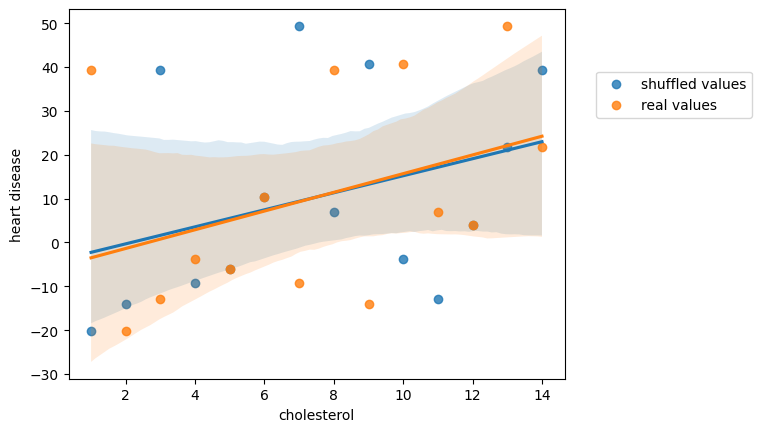

In [280]:
sns.regplot(data=line_to_fit,x="shuffle_x",y="y",label = "shuffled values")
sns.regplot(data=line_to_fit,x="x",y="y", label = "real values")

plt.xlabel("cholesterol")
plt.ylabel("heart disease")
plt.legend(bbox_to_anchor=(1.05, .85))

### Let's do the shuffling bit more times and plot the suffled lines each time

Text(0, 0.5, 'heart disease')

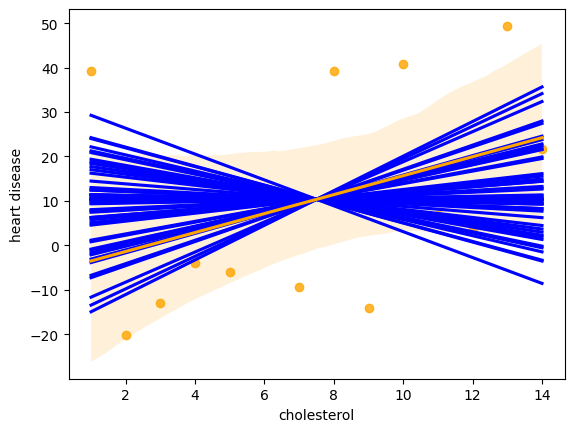

In [281]:
num_rand_lines = 50
for i in np.arange(0,num_rand_lines):
    line_to_fit["shuffle_x"] = np.random.permutation(line_to_fit["x"]).copy()
    sns.regplot(data=line_to_fit,x="shuffle_x",y="y",color="blue",scatter=False,ci=0)
sns.regplot(data=line_to_fit,x="x",y="y",color="orange",label="real values")

plt.xlabel("cholesterol")
plt.ylabel("heart disease")

#### Notice that the 'no relationship' slopes can take a range of values
- They are not all completely flat
- Now you see why our question is a real one
- Is the orange line inside the set of 'no relationship' lines?
- Or is the orange line quite different from those?

### Exercise:  Adapt 'inside the loop' for a full simulation recipe and test whether the slope is different from 0
#### Plot the histogram with 'no relationship' slopes from the simulation and a line for the 'real world' slope
#### Calculate the probability of the 'real world' slope in the 'no relationship' world
- Hint:  Calculate the number of slope values from the 'no relationship world' that are >= 'real world' slope

In [15]:
line_to_fit.head()

,x,y,shuffle_x
0,1,14.243470,5
1,2,14.649771,19
2,3,12.438574,3
3,4,23.270199,4
4,5,26.045374,7


In [282]:
line_to_fit["shuffle_x"] = np.random.permutation(line_to_fit["x"])
x_values = line_to_fit["shuffle_x"]
y_values = line_to_fit["y"]
result = optimize.minimize(sse,[1,5], args=(x_values,y_values))
print(result)
result["x"][0]

  message: Desired error not necessarily achieved due to precision loss.
  success: False
   status: 2
      fun: 7113.572468991345
        x: [-6.929e-01  1.555e+01]
      nit: 8
      jac: [ 1.221e-04  6.104e-05]
 hess_inv: [[ 3.132e-06 -3.139e-05]
            [-3.139e-05  5.032e-02]]
     nfev: 39
     njev: 13


np.float64(-0.6928972246830879)

real slope:  2.132477485456901


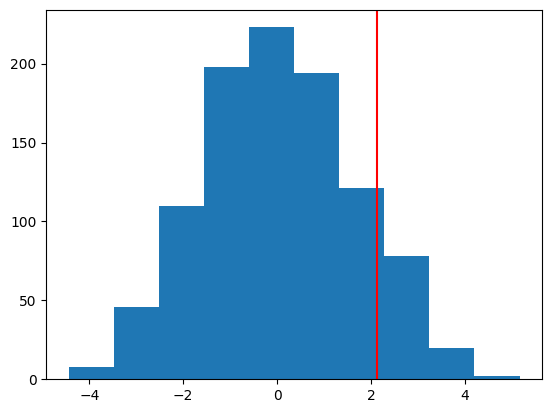

In [283]:
# we already have line_to_fit and real_slope from above.
# line_to_fit has columns for x, y and shuffle_x
x_values = line_to_fit["x"]
y_values = line_to_fit["y"]
real_result = optimize.minimize(sse,[1,5], args=(x_values,y_values))
print("real slope: ",real_result["x"][0])

# our usual 'recipe' for a loop
num_simulations = 1000
# save space for our critical value
slope_values = np.zeros(num_simulations)
# do the loop
for i in np.arange(0,num_simulations):
    # do some stuff in the loop here


# plot the outcome
plt.hist(slope_values)
plt.axvline(real_result["x"][0], color="red")

# we haven't done anything yet, so the plot will just be a bar at zero

In [284]:
number_ge_real_result = np.count_nonzero(slope_values >= real_result["x"][0])
probability = number_ge_real_result/num_simulations
probability

0.114